<a href="https://colab.research.google.com/github/nurbiya-cloud/marketing_analysis/blob/copilot%2Fcreate-repository-structure/P_3_Customer_Behavior_Analysis_%5BPROBLEM%5D.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

student name:**wubu nuerbiya**

student number:**0873194**





# E-commerce data EDA for Customer Behavior Analysis

EDA (Exploratory Data Analysis) of E-Commerce data will help us understand the data and think of ways to use it to understand the customer behavior.

## 1. Load libraries

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import plotly.express as px
from matplotlib.gridspec import GridSpec

## 2. Load Data

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# read in the data (downloaded from Kaggle)
cb_df = pd.read_csv("/content/drive/MyDrive/semester 3/Marketing analytics/project/lab3/Customer_Behavior_Data.csv", delimiter=';')

# print the first 5 rows
cb_df.head()

,account length,location code,user id,credit card info save,push status,add to wishlist,desktop sessions,app sessions,desktop transactions,total product detail views,session duration,promotion clicks,avg order value,sale product views,discount rate per visited products,product detail view per app session,app transactions,add to cart per session,customer service calls,churn
0,128,415,3824657,no,yes,25,265,45,17,110,197,87,"244,7",91,"11,01",10,3,"2,7",1,0
1,107,415,3717191,no,yes,26,162,27,17,123,196,103,"254,4",103,"11,45","13,7",3,"3,7",1,0
2,137,415,3581921,no,no,0,243,41,10,114,121,110,"162,6",104,"7,32","12,2",5,"3,29",0,0
3,84,408,3759999,yes,no,0,299,51,5,71,62,88,"196,9",89,"8,86","6,6",7,"1,78",2,0
4,75,415,3306626,yes,no,0,167,28,13,113,148,122,"186,9",121,"8,41","10,1",3,"2,73",3,0


In [ ]:
cb_df.shape

(3333, 20)

## EDA

With every new dataset we need to got throuhg an EDA (Exploratory Data Analysis) process. It's a good idea to have a basic framework in mind for our EDAs. It is always a good idea to:

- Understand what our columns say
- Rename columns labels and make them lowercase
- Make sure that the data types of columns are correct
- Handle missing values
- Check for duplicates
- Search for outliers
- Check for linearity between variables

To achieve this we can take advantage of Pandas and visualisation libraries

In [ ]:
# Check column names
cb_df.columns

Index(['account length', 'location code', 'user id', 'credit card info save',
       'push status', 'add to wishlist', 'desktop sessions', 'app sessions',
       'desktop transactions', 'total product detail views',
       'session duration', 'promotion clicks', 'avg order value',
       'sale product views', 'discount rate per visited products',
       'product detail view per app session', 'app transactions',
       'add to cart per session', 'customer service calls', 'churn'],
      dtype='object')

In [ ]:
# Rename columns to make them more 'pythonic' by replacing spaces with underscores
cb_df.columns = cb_df.columns.str.replace(' ', '_')

cb_df.columns

Index(['account_length', 'location_code', 'user_id', 'credit_card_info_save',
       'push_status', 'add_to_wishlist', 'desktop_sessions', 'app_sessions',
       'desktop_transactions', 'total_product_detail_views',
       'session_duration', 'promotion_clicks', 'avg_order_value',
       'sale_product_views', 'discount_rate_per_visited_products',
       'product_detail_view_per_app_session', 'app_transactions',
       'add_to_cart_per_session', 'customer_service_calls', 'churn'],
      dtype='object')

In [ ]:
# check the column types and some basic information of the data with the .info() function
cb_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3333 entries, 0 to 3332
Data columns (total 20 columns):
 #   Column                               Non-Null Count  Dtype 
---  ------                               --------------  ----- 
 0   account_length                       3333 non-null   int64 
 1   location_code                        3333 non-null   int64 
 2   user_id                              3333 non-null   int64 
 3   credit_card_info_save                3333 non-null   object
 4   push_status                          3333 non-null   object
 5   add_to_wishlist                      3333 non-null   int64 
 6   desktop_sessions                     3333 non-null   int64 
 7   app_sessions                         3333 non-null   int64 
 8   desktop_transactions                 3333 non-null   int64 
 9   total_product_detail_views           3333 non-null   int64 
 10  session_duration                     3333 non-null   int64 
 11  promotion_clicks                     3333 n

In [ ]:
# change the data-type of the 4 columns to float
cb_df['avg_order_value'] = cb_df['avg_order_value'].replace(',','.', regex=True).astype(float)
cb_df['discount_rate_per_visited_products'] = cb_df['discount_rate_per_visited_products'].replace(',','.', regex=True).astype(float)
cb_df['add_to_cart_per_session'] = cb_df['add_to_cart_per_session'].replace(',','.', regex=True).astype(float)
cb_df['product_detail_view_per_app_session'] = cb_df['product_detail_view_per_app_session'].replace(',','.', regex=True).astype(float)

# Convert data-type of the 2 columns to category/object datatype
cb_df['location_code'] = cb_df['location_code'].astype(str)
cb_df['user_id'] = cb_df['user_id'].astype(str)


cb_df.dtypes

,0
account_length,int64
location_code,object
user_id,object
credit_card_info_save,object
push_status,object
add_to_wishlist,int64
desktop_sessions,int64
app_sessions,int64
desktop_transactions,int64
total_product_detail_views,int64


In [ ]:
# Map 'yes'/'no' to 1/0 for binary columns
binary_mapping = {'yes': 1, 'no': 0}

cb_df['credit_card_info_save'] = cb_df['credit_card_info_save'].map(binary_mapping).astype('int64')
cb_df['push_status'] = cb_df['push_status'].map(binary_mapping).astype('int64')

# Verify the updated data types and values
display(cb_df[['credit_card_info_save', 'push_status', 'churn']].dtypes)
display(cb_df[['credit_card_info_save', 'push_status', 'churn']].head())

,0
credit_card_info_save,int64
push_status,int64
churn,int64


,credit_card_info_save,push_status,churn
0,0,1,0
1,0,1,0
2,0,0,0
3,1,0,0
4,1,0,0




---



In [ ]:
cb_df.dtypes

,0
account_length,int64
location_code,object
user_id,object
credit_card_info_save,int64
push_status,int64
add_to_wishlist,int64
desktop_sessions,int64
app_sessions,int64
desktop_transactions,int64
total_product_detail_views,int64


## Statistical Analysis

Are there missing values in the data? (see .info() results) so we can move on and check our descriptive statistics with the .describe() function.

In [ ]:
# 1. Identify all numerical columns
numeric_cols = cb_df.select_dtypes(include=['int64', 'float64']).columns.tolist()

# 2. Filter out binary columns (columns with exactly 2 unique values like churn, credit_card_info_save, push_status)
continuous_numeric_cols = [col for col in numeric_cols if cb_df[col].nunique() > 2]

# 3. Display descriptive statistics only for true continuous numerical columns
display(cb_df[continuous_numeric_cols].describe().T)

,count,mean,std,min,25%,50%,75%,max
account_length,3333.0,101.064806,39.822106,1.00,74.00,101.00,127.00,243.00
add_to_wishlist,3333.0,8.099010,13.688365,0.00,0.00,0.00,20.00,51.00
desktop_sessions,3333.0,179.811881,54.457135,0.00,144.00,179.00,216.00,351.00
app_sessions,3333.0,30.567957,9.269376,0.00,24.00,31.00,37.00,60.00
desktop_transactions,3333.0,17.087609,4.323795,0.00,14.00,17.00,20.00,31.00
total_product_detail_views,3333.0,100.435644,20.069084,0.00,87.00,101.00,114.00,165.00
session_duration,3333.0,201.039604,50.714359,0.00,167.00,201.00,235.00,364.00
promotion_clicks,3333.0,100.110711,19.923911,0.00,87.00,100.00,114.00,170.00
avg_order_value,3333.0,200.872037,50.573847,23.20,167.00,201.20,235.30,395.00
sale_product_views,3333.0,100.107711,19.568609,33.00,87.00,100.00,113.00,175.00


## Search for outliers

- Outliers are data points at the extreme points of a dataset.
- Some outliers represent true values from natural variation in the population and some occur because of dirty or incorect data.
    - Because of this, we need to be careful when we cleanse our data
    - If the outliers are True outliers, we should probably keep them in our data since they represent natural variations in our sample
    - If the outliers are errors we should generally remove those data points
    
We've already identified some potential outliers from our .describe() function with session durations, average order value, promotion clicks, sale product views, app transactions, account length, add to wish list, desktop sessions, and customer service calls.

To identify our outliers we can use:
- Visualisations such as histograms and blox plots
- Use interquartiles with rules such as:
    - outlier < Q1 - 1.5(IQR)
    - outlier > Q3 + 1.5(IQR)

In [ ]:
# Plot interactive histograms and box plots for all continuous numerical columns to identify outliers
for col in continuous_numeric_cols:
    # Create a histogram
    hist_fig = px.histogram(cb_df, x=col, title=f'Histogram of {col.replace("_", " ").title()}')
    hist_fig.show()

    # Create a box plot
    box_fig = px.box(cb_df, y=col, title=f'Box Plot of {col.replace("_", " ").title()}')
    box_fig.show()

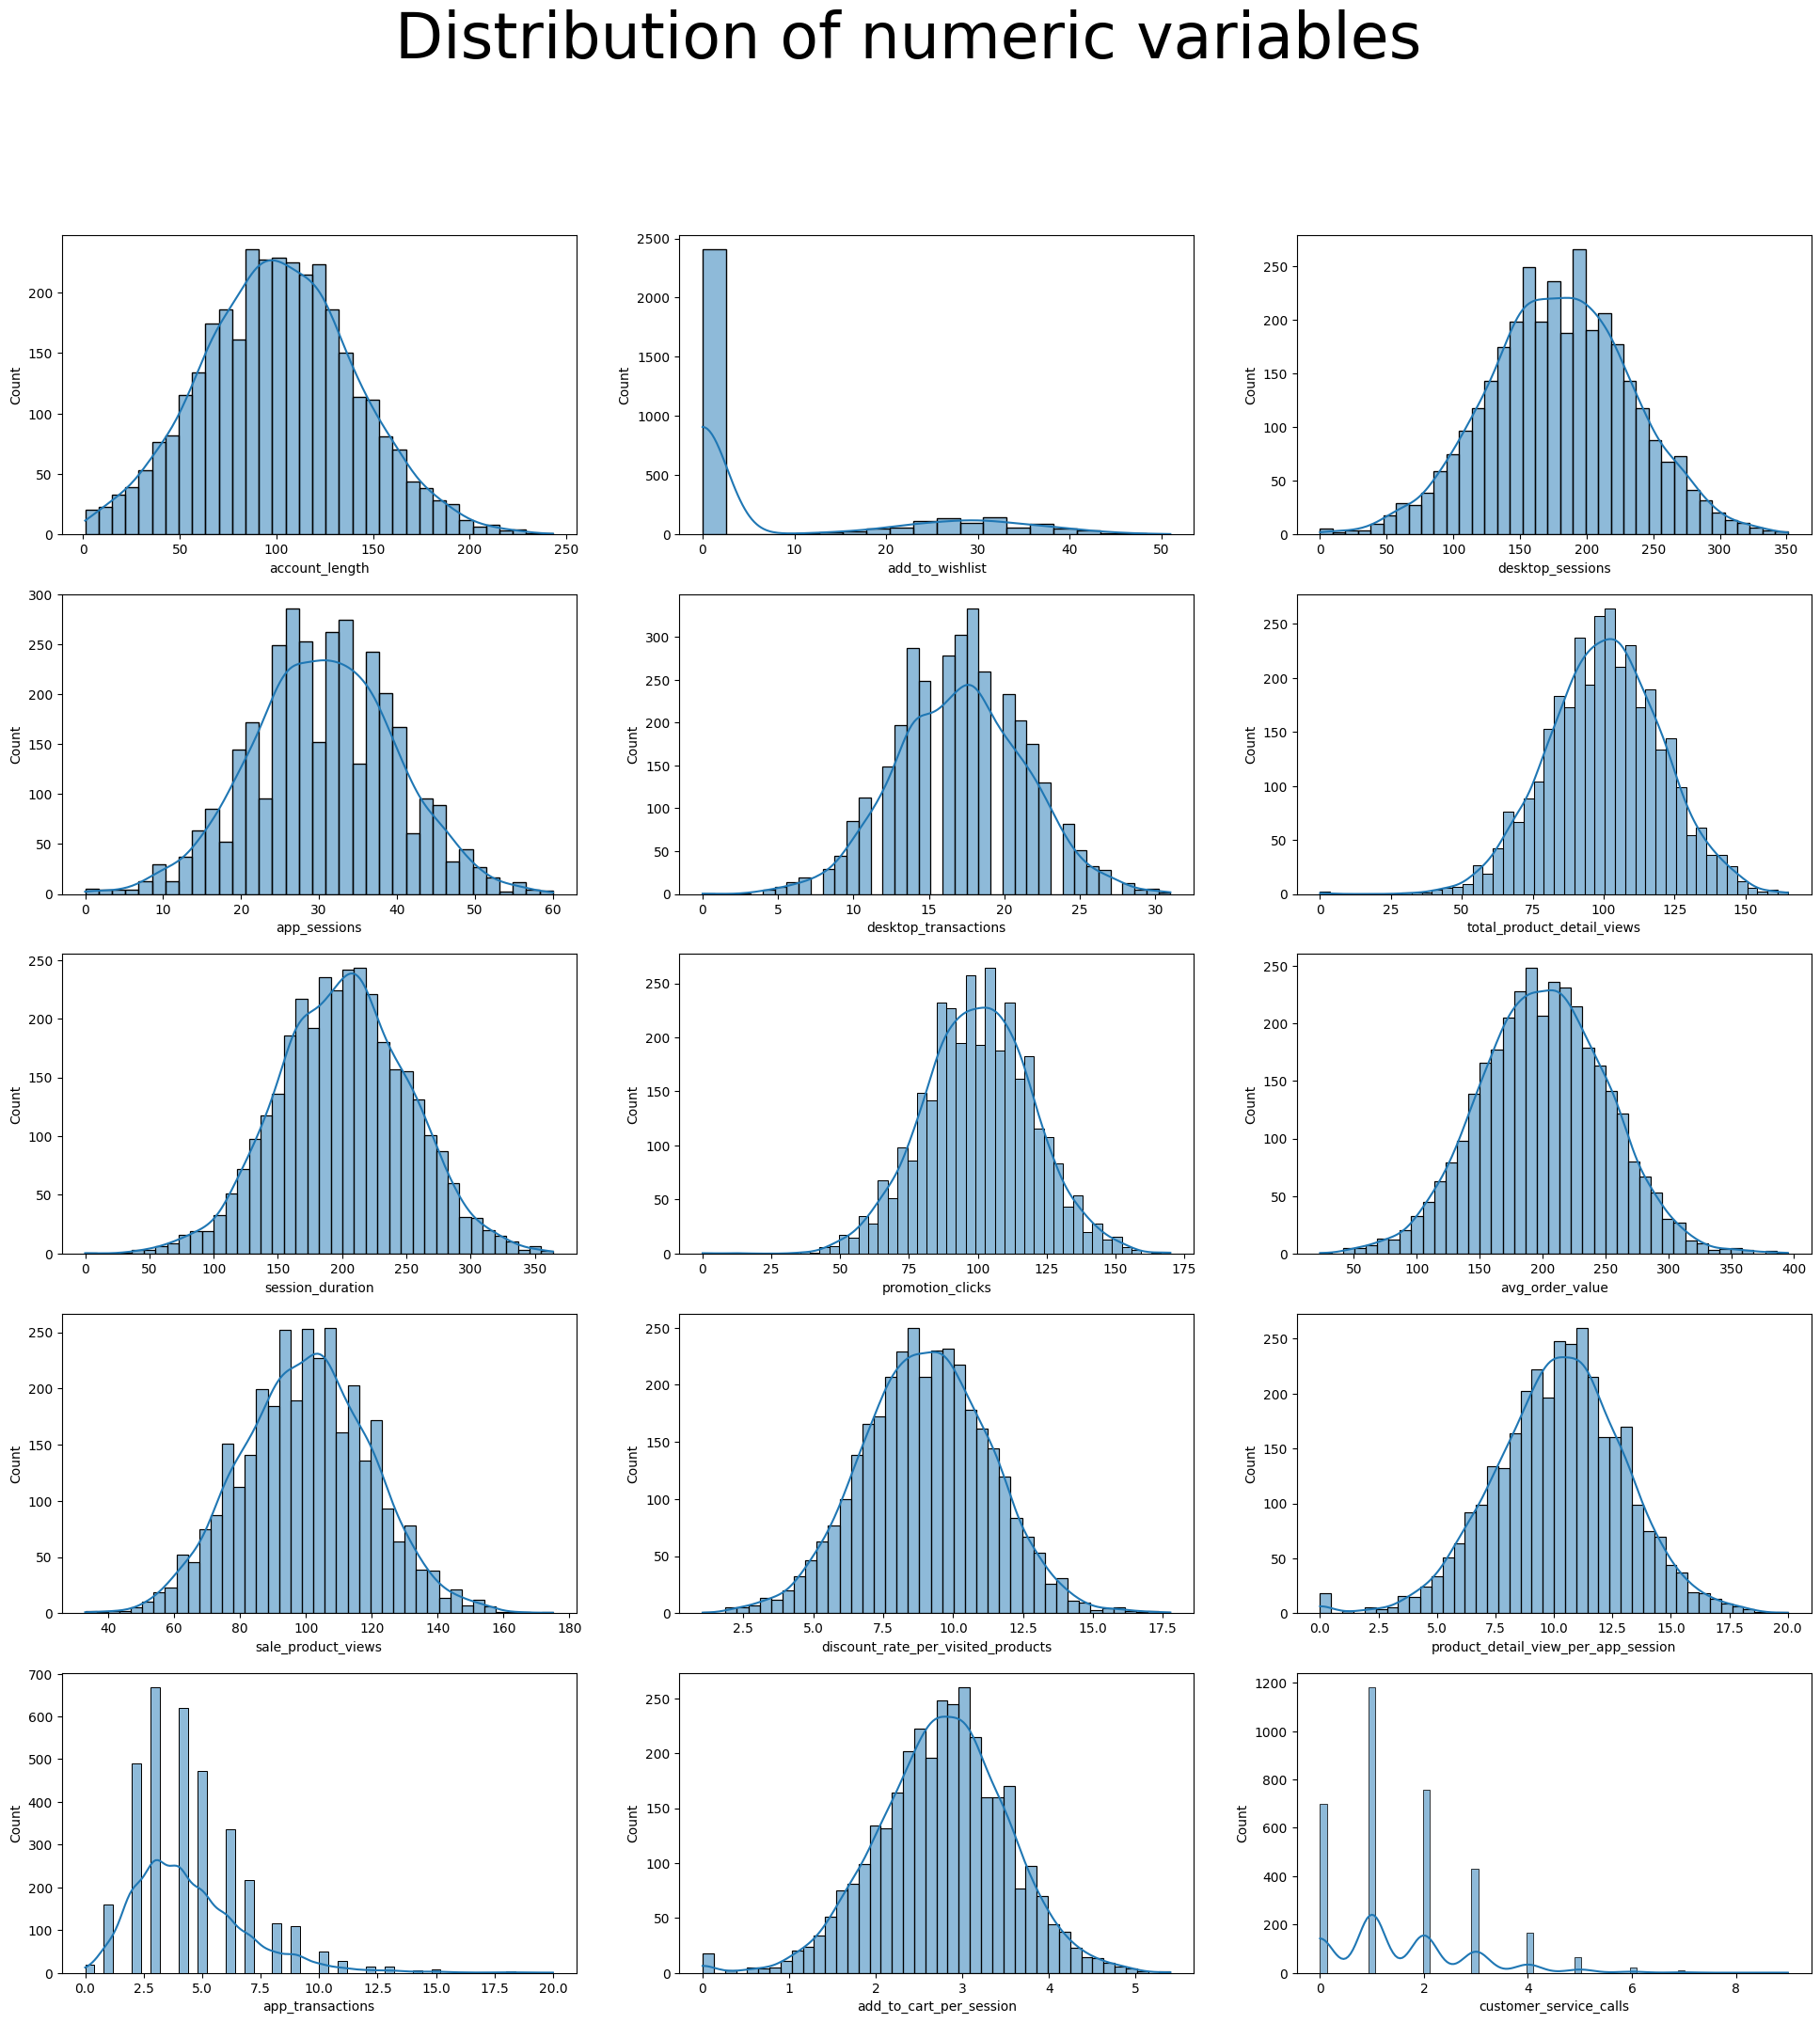

In [ ]:
# An alternative way to plot the distribution of all numeric variables in one go is the below

## Create a list of the numeric variables
numeric_columns = ['account_length', 'add_to_wishlist', 'desktop_sessions','app_sessions', 'desktop_transactions',
                   'total_product_detail_views','session_duration', 'promotion_clicks', 'avg_order_value','sale_product_views',
                   'discount_rate_per_visited_products','product_detail_view_per_app_session', 'app_transactions',
                   'add_to_cart_per_session', 'customer_service_calls']

fig, axes = plt.subplots(5,3, figsize=(24,24))
fig.suptitle("Distribution of numeric variables", size=48)

for i in range(5):
    for j in range(3):
        sns.histplot(cb_df[numeric_columns[3*i+j]], ax=axes[i,j], kde=True)

### 📊 Key Findings: Distribution of Numeric Variables

* **Normal Distributions**: Account length, desktop sessions, app sessions, desktop transactions, product views, and session durations all follow relatively clean normal distributions, suggesting standard behavioral patterns among the user base.
* **Zero Inflation**: Both `add_to_wishlist` and `customer_service_calls` are highly zero-inflated, meaning the majority of customers do not utilize these actions, but a small tail of customers uses them extensively.

### Summary of Abnormal Values & Outlier Handling Strategy

#### 1. Detected Outliers / Abnormal Values
* **Extreme Activity Metrics**: Columns like `desktop_sessions` (max 351), `app_sessions` (max 60), and `add_to_wishlist` (max 51) have maximum values significantly higher than their 75th percentiles. These represent highly active power-users.
* **Customer Service Complaints**: `customer_service_calls` has a maximum of 9, whereas the median is 1. Customers making 9 calls are extreme outliers and likely highly prone to churn.
* **High Spenders / Long Sessions**: `avg_order_value` (max 395.00) and `session_duration` (max 364 min) display extreme values indicating high-value user sessions.

#### 2. Handling Methods
* **Retention (Recommended)**: These are **True Outliers**. In customer behavior data, extreme engagement or high complaint rates are legitimate behaviors that help predict `churn` accurately. Deleting them would remove valuable predictive patterns.
* **Transformation (for Modeling)**: When using linear models, we can apply a log-transformation `np.log1p()` to skewed columns to minimize outlier influence without losing observations.

In [ ]:
# Show the count of 1s and 0s for each binary column
for col in ['credit_card_info_save', 'push_status', 'churn']:
    print(f"Value counts for '{col}':")
    print(cb_df[col].value_counts())
    print("-" * 30)

Value counts for 'credit_card_info_save':
credit_card_info_save
0    3010
1     323
Name: count, dtype: int64
------------------------------
Value counts for 'push_status':
push_status
0    2411
1     922
Name: count, dtype: int64
------------------------------
Value counts for 'churn':
churn
0    2850
1     483
Name: count, dtype: int64
------------------------------


In [ ]:
# descriptive statistics for non-numeric columns (after the conversion)
cb_df.describe(exclude= np.number)

,location_code,user_id
count,3333,3333
unique,3,3333
top,415,3824657
freq,1655,1


In [ ]:
cb_df['location_code'].value_counts()

,count
location_code,
415,1655
510,840
408,838


## 3. Handle Missing Values

Missing values can be an issue with most real-life datasets. We can use the .info() function, there are no missing values. For the sake of double checking and to show a way of checking whether the dataset has missing values, let's write some code below

In [ ]:
# Check missing values and sort data by descending order
cb_df.isnull().sum().sort_values(ascending=False)

,0
account_length,0
location_code,0
user_id,0
credit_card_info_save,0
push_status,0
add_to_wishlist,0
desktop_sessions,0
app_sessions,0
desktop_transactions,0
total_product_detail_views,0


### Observation on Missing Values:
As shown in the output above, every column returned `0` missing values. This confirms that there are absolutely no null or missing (`NaN` / `None`) values in this dataset, and we can proceed with our analysis without needing any data imputation.
```

## 4. Check for duplicates

Another common issue with data is duplicated records. We need to make sure to always check for duplicates

In [ ]:
# Let's start by checking whether all user ids are unique
## If we find duplicated user ids we'll have to understand if there is a reason for appearing more than once in the data
cb_df.user_id.nunique()

3333

### Observation on Duplicate Check:
The total number of unique user IDs is **3,333**, which perfectly matches the total number of rows in our dataset (`cb_df.shape` is `(3333, 20)`).

* **Do we need to check other columns?** No. Since `user_id` is unique for every single row, we have confirmed that there are no duplicate user records in this dataset. Other columns (such as `location_code`, activity metrics, or `churn`) are expected to have repeated values because multiple different users can live in the same location, have similar usage patterns, or share the same churn status.

# 5. Analysis of the Dependent variable (Churn) vs Idependent variables

Until now we've looked into the numeric variables, their missing data, duplicates, distribution, and outliers. A key part of the customer behaviour data is to understand which "behaviours" aka idependent varialbes in our dataset can help us predict customers deciding to stop using the product, aka "churn".

Another variable that we haven't analysed yet is the location code, but we might be able to find value in comparing it with the churn and finding out any potential correlations.

In [ ]:
cb_df.churn.dtype

dtype('int64')

In [ ]:
cb_df['churn'] = cb_df['churn'].astype('int')

/tmp/ipykernel_12837/2417424428.py:8: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




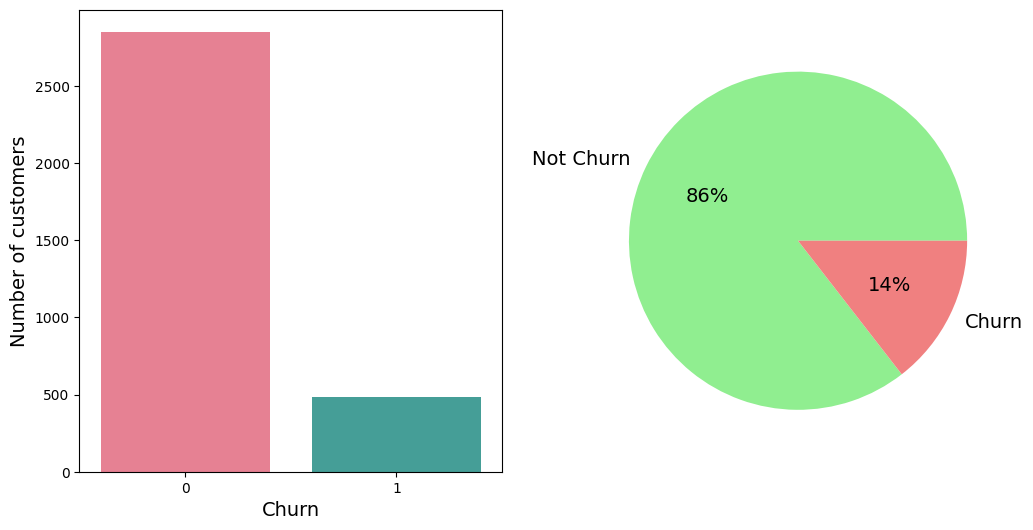

In [ ]:
# define subplots
fig, ax = plt.subplots(1,2,figsize= (12,6))

# create the pie plot for the percentage opf churn and not churn customers
plt.pie(cb_df.churn.value_counts(),labels = ["Not Churn", "Churn"], colors = ["lightgreen", "lightcoral"], autopct='%.0f%%', textprops={'fontsize': 14})

# create a bar plot counting the number of customers that are churn 0 and churn 1
cp = sns.countplot(x=cb_df['churn'], ax = ax[0], palette = 'husl')

cp.set_xlabel("Churn", fontsize=14)

cp.set_ylabel("Number of customers", fontsize=14)

plt.show()

### 📊 Key Findings: Overall Churn Distribution

* **Class Imbalance**: The dataset displays a notable class imbalance, with **86%** of customers remaining active (Not Churn) and **14%** of customers leaving the service (Churn).
* **Baseline Metric**: Any predictive model we build must perform significantly better than a naive baseline model of 86% accuracy. Our focus should be on recall for the churned class (1) to capture as many leaving customers as possible.

Plot binary and categorical data

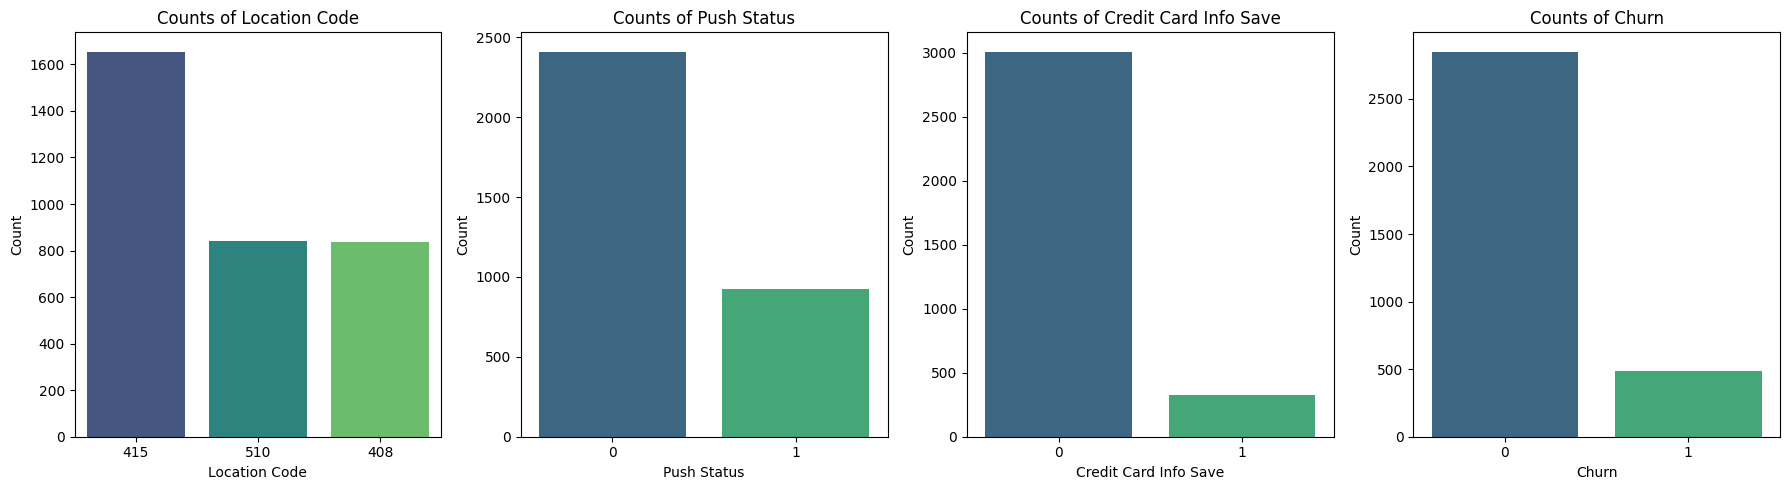

In [ ]:
# Define categorical and binary columns to visualize
bin_categorical_columns = ["location_code", "push_status", "credit_card_info_save", "churn"]

# Set up side-by-side bar plots
fig, ax = plt.subplots(1, len(bin_categorical_columns), figsize=(18, 5))

for idx, col in enumerate(bin_categorical_columns):
    temp = cb_df[col].value_counts()
    sns.barplot(ax=ax[idx], x=temp.index, y=temp.values, hue=temp.index, legend=False, palette='viridis')
    ax[idx].set_title(f"Counts of {col.replace('_', ' ').title()}")
    ax[idx].set_xlabel(col.replace('_', ' ').title())
    ax[idx].set_ylabel("Count")

plt.tight_layout()
plt.show()

### 📊 Key Findings: Categorical and Binary Column Counts

* **Location Code**: Region `415` has twice as many users (~1,655) compared to regions `408` (~838) and `510` (~840), indicating where the bulk of the customer base is situated.
* **Push Status**: Only a minority (~922) of users have push notifications enabled, while the vast majority (~2,411) keep them turned off.
* **Credit Card Info**: Only a small fraction of users (~323) choose to save their credit card information, suggesting potential trust barriers or friction during checkout.

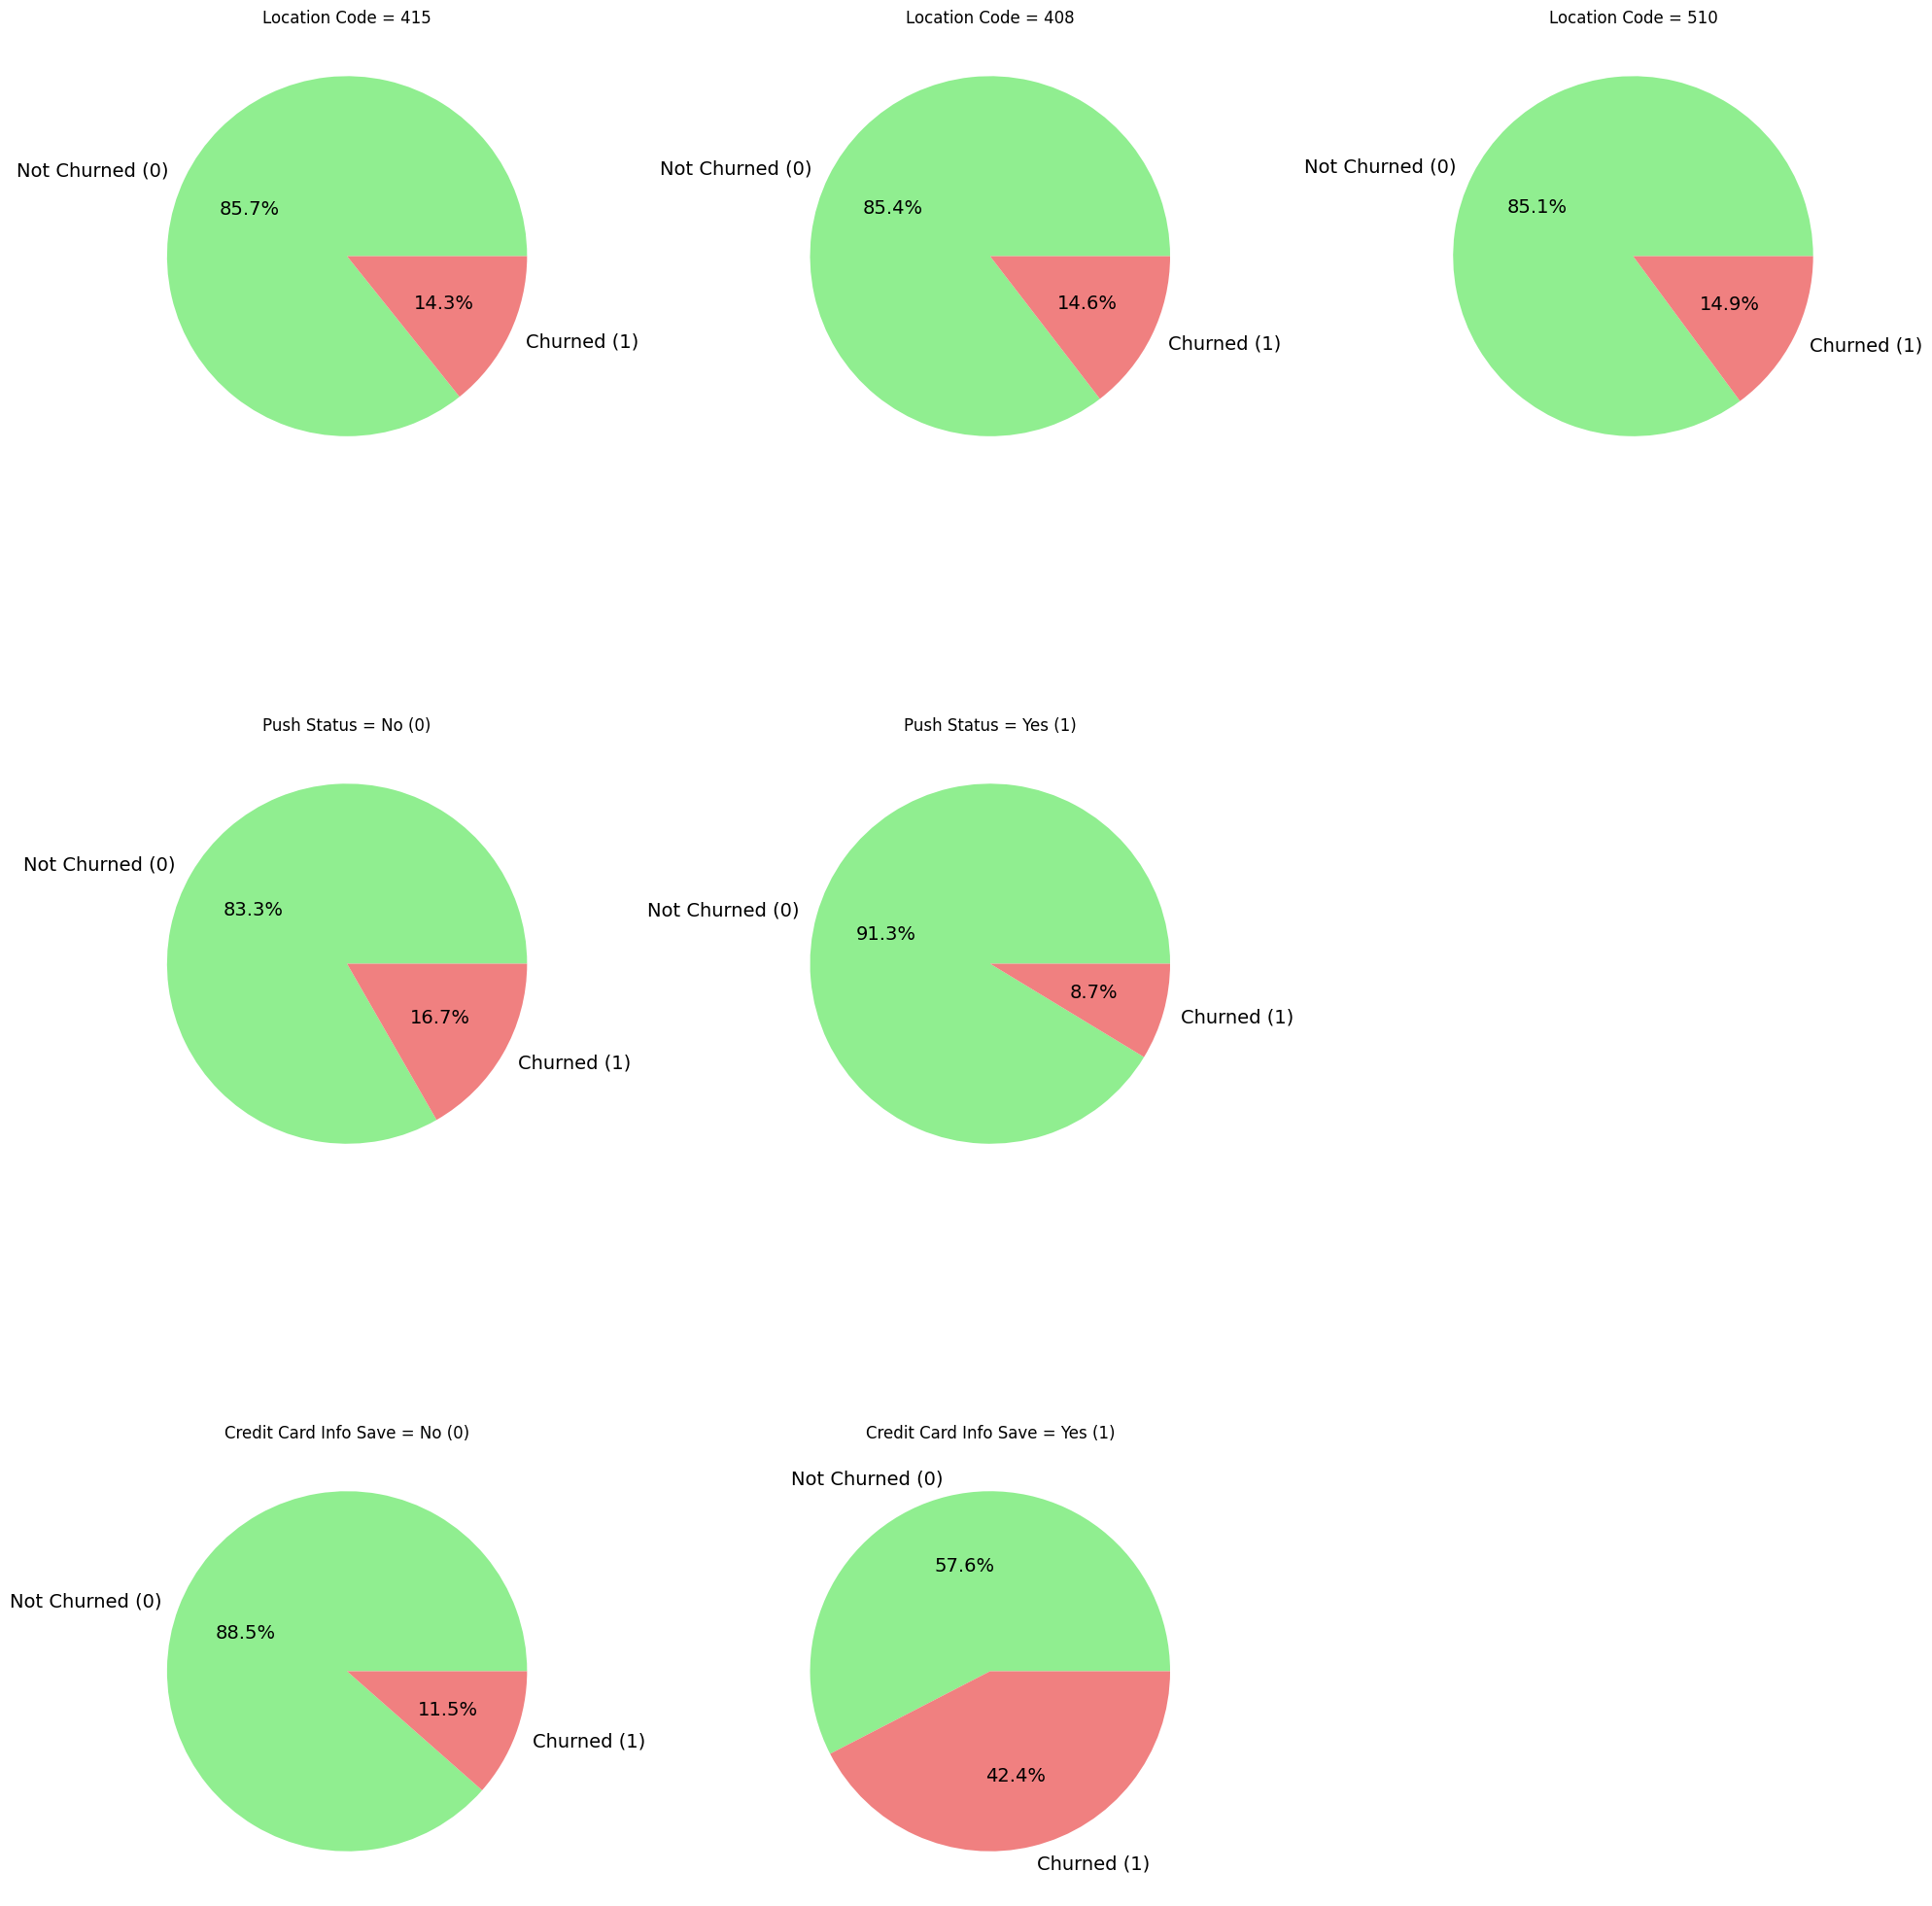

In [ ]:
# Plot the relationship between each categorical feature and churn rate
plt.figure(1, figsize=(20, 22))
the_grid = GridSpec(3, 3)

# Define uniform labels and colors for consistency in Churn representation
labels = ['Not Churned (0)', 'Churned (1)']
colors = ['lightgreen', 'lightcoral']

# 1. Location Code Churn Proportions
# Location Code = '415'
plt.subplot(the_grid[0, 0], aspect=1, title='Location Code = 415')
counts_415 = cb_df[cb_df['location_code'] == '415']['churn'].value_counts().reindex([0, 1], fill_value=0)
plt.pie(counts_415, labels=labels, colors=colors, autopct='%.1f%%', textprops={'fontsize': 14})

# Location Code = '408'
plt.subplot(the_grid[0, 1], aspect=1, title='Location Code = 408')
counts_408 = cb_df[cb_df['location_code'] == '408']['churn'].value_counts().reindex([0, 1], fill_value=0)
plt.pie(counts_408, labels=labels, colors=colors, autopct='%.1f%%', textprops={'fontsize': 14})

# Location Code = '510'
plt.subplot(the_grid[0, 2], aspect=1, title='Location Code = 510')
counts_510 = cb_df[cb_df['location_code'] == '510']['churn'].value_counts().reindex([0, 1], fill_value=0)
plt.pie(counts_510, labels=labels, colors=colors, autopct='%.1f%%', textprops={'fontsize': 14})

# 2. Push Status Churn Proportions
# Push Status = 0
plt.subplot(the_grid[1, 0], aspect=1, title='Push Status = No (0)')
counts_push_0 = cb_df[cb_df['push_status'] == 0]['churn'].value_counts().reindex([0, 1], fill_value=0)
plt.pie(counts_push_0, labels=labels, colors=colors, autopct='%.1f%%', textprops={'fontsize': 14})

# Push Status = 1
plt.subplot(the_grid[1, 1], aspect=1, title='Push Status = Yes (1)')
counts_push_1 = cb_df[cb_df['push_status'] == 1]['churn'].value_counts().reindex([0, 1], fill_value=0)
plt.pie(counts_push_1, labels=labels, colors=colors, autopct='%.1f%%', textprops={'fontsize': 14})

# 3. Credit Card Info Save Churn Proportions
# Credit Card Info Save = 0
plt.subplot(the_grid[2, 0], aspect=1, title='Credit Card Info Save = No (0)')
counts_cc_0 = cb_df[cb_df['credit_card_info_save'] == 0]['churn'].value_counts().reindex([0, 1], fill_value=0)
plt.pie(counts_cc_0, labels=labels, colors=colors, autopct='%.1f%%', textprops={'fontsize': 14})

# Credit Card Info Save = 1
plt.subplot(the_grid[2, 1], aspect=1, title='Credit Card Info Save = Yes (1)')
counts_cc_1 = cb_df[cb_df['credit_card_info_save'] == 1]['churn'].value_counts().reindex([0, 1], fill_value=0)
plt.pie(counts_cc_1, labels=labels, colors=colors, autopct='%.1f%%', textprops={'fontsize': 14})

plt.tight_layout()
plt.show()

### 📊 Categorical Features vs. Churn Analysis: Key Findings

Based on the grid of pie charts comparing our categorical and binary attributes to the Churn rate, here are the core observations:

1. **Location Code:**
   * The proportion of churned customers is extremely consistent across all three regions (ranging from **14.3% in '415'** to **14.9% in '510'**).
   * **Takeaway:** Geographical location does not appear to be a major driver or indicator of customer churn.

2. **Push Notifications (`push_status`):**
   * Customers with push notifications disabled ($0$) have a churn rate of **16.7%**.
   * Customers with push notifications enabled ($1$) have a significantly lower churn rate of **8.7%**.
   * **Takeaway:** Encouraging or incentivizing users to turn on push notifications could be an effective engagement mechanism to minimize overall churn.

3. **Credit Card Saving Status (`credit_card_info_save`):**
   * Customers who do not save their credit cards have a churn rate of **11.5%**.
   * Customers who have saved their credit card information experience a massive churn rate of **42.4%**.
   * **Takeaway:** This is an alarmingly high churn segment! While saving card info usually represents convenience, users who actively keep financial info on file might expect seamless automated transactions, and any friction, subscription renewals, or billing surprises might trigger instant cancellations. This segment needs further diagnostic deep-dives.